![Manhattan Urban Forest](cover.png)

In [2]:
# import the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

#import src.style # A file which helps me style all the plots more consistently

In [3]:
# READ logs excel file  & PRINT BASIC FACTS ===================================
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.shape)
print("*************************")
print(df.info())
print("*************************")
print(df.describe())
print("*************************")
print(df.isna().sum())


(7043, 21)
*************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paper

We noticed: TotalCharges → object even though it should be numeric.
we shall inspect this feature and convert the values into numeric type 

In [5]:
print(df["TotalCharges"].dtype)
print("********************************")
print(df["TotalCharges"].value_counts().tail(20))
print("*********************************")
print(pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum())

object
********************************
1185       1
1838.15    1
1263.9     1
2447.45    1
1140.05    1
5064.45    1
2065.15    1
3838.2     1
168.9      1
7843.55    1
3306.85    1
424.75     1
6565.85    1
2117.2     1
203.95     1
6849.4     1
692.35     1
130.15     1
3211.9     1
6844.5     1
Name: TotalCharges, dtype: int64
*********************************
11


In [6]:
bad_total = df[pd.to_numeric(df["TotalCharges"], errors="coerce").isna()]

print(bad_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


In [7]:
print(repr(df.loc[bad_total.index[0], "TotalCharges"]))

' '


## Data cleaning

In [8]:
#replace spaces with "0" then we convert "0" to nuumeric 0
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

#verify results after data cleaning 
print(df["TotalCharges"].dtype)
print(df["TotalCharges"].isna().sum())

print(df.loc[bad_total.index, 
             ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])


float64
0
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55           0.0
753   3115-CZMZD       0           20.25           0.0
936   5709-LVOEQ       0           80.85           0.0
1082  4367-NUYAO       0           25.75           0.0
1340  1371-DWPAZ       0           56.05           0.0
3331  7644-OMVMY       0           19.85           0.0
3826  3213-VVOLG       0           25.35           0.0
4380  2520-SGTTA       0           20.00           0.0
5218  2923-ARZLG       0           19.70           0.0
6670  4075-WKNIU       0           73.35           0.0
6754  2775-SEFEE       0           61.90           0.0


In [9]:
# check for duplicated entries 
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated customer IDs:", df["customerID"].duplicated().sum())

#check for unique customerId 

print("Unique customer IDs:", df["customerID"].nunique())

print("Number of rows:", len(df))

Duplicated rows: 0
Duplicated customer IDs: 0
Unique customer IDs: 7043
Number of rows: 7043


## EDA 

In [10]:
print(df["Churn"].value_counts())
print(f"{df['Churn'].value_counts(normalize=True) * 100 } %")

No     5174
Yes    1869
Name: Churn, dtype: int64
No     73.463013
Yes    26.536987
Name: Churn, dtype: float64 %


the target is imbalanced 73.5 % of customers don't churn while 26% churn that means that accuracy alone would not be enough to judge the model for example a model that predicts all customers won'tchurn will have a 73.5 % accuracy wich might seam acceptable but for a company trying to retain customers, that would be practically useless.

Now let's investigate whether churn is related to some of our variables.

Let's start with one of the most intuitive ones: Contract

A customer's contract could be:

Month-to-month
One year
Two year

Let's  see the churn rate for each contract type.

In [11]:
print(pd.crosstab(df["Contract"], df["Churn"]))
print(pd.crosstab(df["Contract"], df["Churn"], normalize= "index") * 100)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


What does the above results tell us?

The relationship is very strong.

Customers with a month-to-month contract have a churn rate of about 42.7%.

Compare that with:

One-year contract → 11.3%
Two-year contract → 2.8%

That's a huge difference.

So Contract is likely to be an important predictive feature for our model.

But here's an important distinction:

**_EDA shows us an association; it doesn't prove causation._**

We cannot conclude:

"Month-to-month contracts cause customers to leave."

There could be other factors involved.

For example, perhaps customers who choose month-to-month contracts are also more likely to
- have shorter tenure,
- pay higher monthly charges,
- use certain services,
- have different customer profiles.

Our ML model will consider multiple variables simultaneously.

🎯 Let's investigate another important variable

I want to introduce you to a very common question in churn analysis:

Does customer tenure affect churn?

We have: **tenure** which represents the number of months the customer has been with the company.


In [12]:
print(df.groupby("Churn")["tenure"].mean())
print(df.groupby("Churn")["tenure"].median())

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64
Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64


So customers who churned had much shorter tenure than customers who stayed.

But look at the median carefully

The difference is even more striking:

Customers who stayed: 38 months
Customers who churned: 10 months

That tells us the distribution isn't simply shifted a little. There is a substantial concentration of churned customers among relatively new customers.

And notice something interesting:

Mean churned = 17.98 months, but median churned = 10 months.

That suggests the churned group has some customers with considerably longer tenure pulling the mean upward.

This is exactly why looking at both mean and median is useful.


📊 Now let's visualize it

We've done the numerical analysis. Now let's see the distributions using a boxplot of tenure separated by Churn.

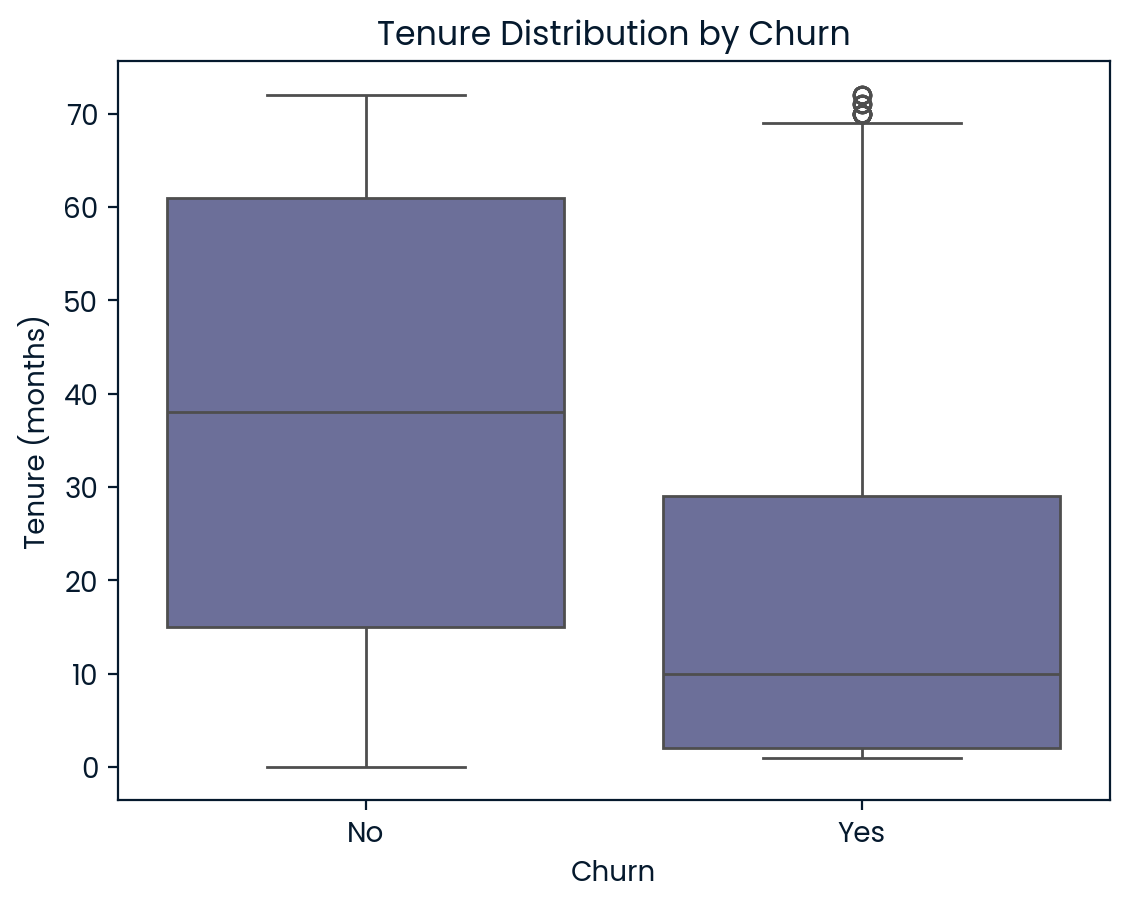

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")
plt.show()

1. Lower median → Yes 🟢

The churned customers have a much lower median tenure.

2. Greater spread → No 🟢

The No group has a wider distribution of tenure.

4. Outliers → Yes 🟢

There are customers who churned despite having relatively long tenure, appearing as outliers.

And this is actually interesting: tenure is strongly associated with churn, but it certainly doesn't determine churn by itself.

4. Supports our hypothesis → 🟢

Yes.

### Now let's investigate another potentially important factor: **Monthly charges**  
Our question is:  Do customers who pay more per month tend to churn more?  
Again, let's make a hypothesis before looking at the data.  Think about the business situation.  A customer paying 90 usd per month might be more sensitive to price than someone paying 20 usd per month.  
But perhaps the opposite could happen because higher-paying customers might also receive more services.

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64
Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64


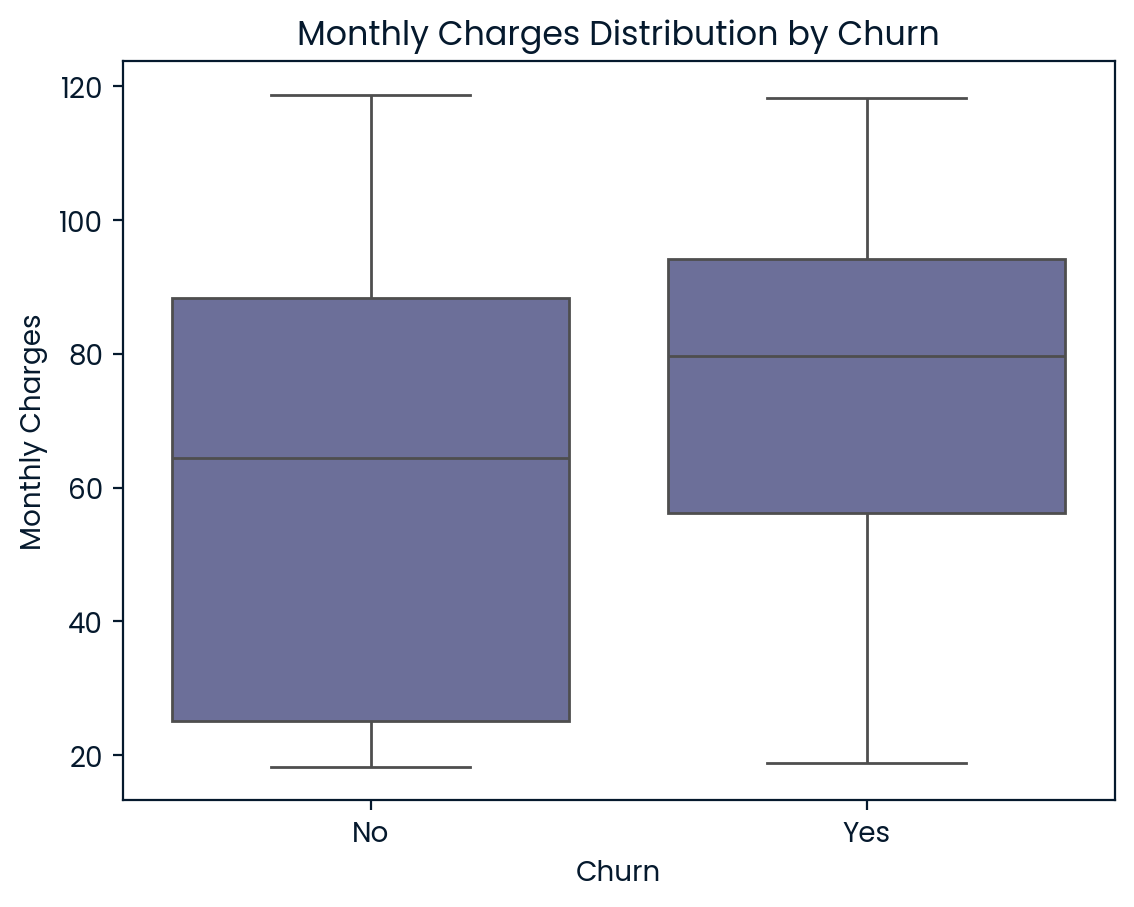

In [14]:
print(df.groupby("Churn")["MonthlyCharges"].mean())
print(df.groupby("Churn")["MonthlyCharges"].median())

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

What we found

The churned (Yes) group has both a higher mean and higher median MonthlyCharges than the customers who stayed.

So our hypothesis is supported:

Customers with higher monthly charges appear more likely to churn in this dataset.

### 🔎 Next EDA: categorical features

We've looked at two numerical variables. Now I'd like to investigate one categorical variable that could be particularly interesting:

**InternetService**

It has categories such as:

- DSL
- Fiber optic
- No inetrnet service

Let's calculate the churn rate for each.

In [15]:
print(
    pd.crosstab(
        df["InternetService"],
        df["Churn"],
        normalize="index"
    ) * 100
)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


So customers with fiber optic have by far the highest observed churn rate 41,81%.

And this gives us a great opportunity to practice something very important:

**⚠️ Don't explain the result too quickly**

We might be tempted to say:

"Fiber optic causes customers to churn."

We cannot conclude that.

Instead:

Fiber optic service is strongly associated with churn in this dataset.

Now our job as data scientists is to ask:

### **Why?**

There could be several explanations.

For example, maybe fiber-optic customers:

- pay substantially more,
- are disproportionately on month-to-month contracts,
- have different tenure,
- experience particular service problems,
- or belong to another customer segment.

And this is where multivariable analysis becomes interesting.


Month-to-month → 42.7% churn

Fiber optic → 41.8% churn

these two variables could be related to each other?

For example, perhaps a large proportion of fiber-optic customers are also month-to-month customers.

If that's true, then part of the apparent relationship between fiber and churn could be explained by the contract type.

In [16]:
print(pd.crosstab(df["InternetService"], df["Contract"]))
print(pd.crosstab(df["InternetService"], df["Contract"], normalize="index")*100)

Contract         Month-to-month  One year  Two year
InternetService                                    
DSL                        1223       570       628
Fiber optic                2128       539       429
No                          524       364       638
Contract         Month-to-month   One year   Two year
InternetService                                      
DSL                   50.516316  23.543990  25.939694
Fiber optic           68.733850  17.409561  13.856589
No                    34.338139  23.853211  41.808650


So 68.7% of fiber-optic customers are month-to-month, compared with only 50.5% of DSL customers.

Remember what we discovered earlier:

**Contract → Churn**

Month-to-month → 42.7% churn

And now:

**InternetService → Contract**

Fiber optic → 68.7% month-to-month ,DSL → 50.5% month-to-month

And we also observed:

**InternetService → Churn**

Fiber optic → 41.8% churn , DSL → 19.0% churn ,No internet → 7.4% churn

So we have a chain of associations:

**Fiber optic → more month-to-month customers → month-to-month has much higher churn**

This is a very interesting hypothesis.

But be careful: we cannot yet say that contract type explains all of the higher fiber-optic churn. There may be other factors involved, such as:

Monthly charges
Tenure
Payment method
Tech support
Online security
Device protection
etc.

This is exactly how real-world EDA should work: you discover something → form a hypothesis → investigate another variable.

Now I want to answer a more interesting question:

Is the high churn among fiber-optic customers still present when we compare customers with the same contract type?

In [17]:
print(pd.crosstab(
    [df["InternetService"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100)

Churn                                  No        Yes
InternetService Contract                            
DSL             Month-to-month  67.784137  32.215863
                One year        90.701754   9.298246
                Two year        98.089172   1.910828
Fiber optic     Month-to-month  45.394737  54.605263
                One year        80.705009  19.294991
                Two year        92.773893   7.226107
No              Month-to-month  81.106870  18.893130
                One year        97.527473   2.472527
                Two year        99.216301   0.783699


Look at what happened:

Among month-to-month customers, fiber churn is 54.6% vs DSL 32.2% and No service 18.9%.
Among one-year customers, fiber churn is 19.3% vs DSL 9.3% and No service 2.47%.
Among two-year customers, fiber churn is 7.2% vs DSL 1.9% and No service 0.78%.

So our answer is:

Yes. Fiber-optic customers still have substantially higher churn than DSL and No service customers even when we hold contract type constant.

Remember our previous hypothesis:

"Maybe fiber has high churn simply because fiber customers are more likely to be month-to-month."

Our analysis tells us:

That's only part of the explanation, So there appears to be another factor associated with fiber-optic churn.

We still shouldn't say: **"Fiber optic causes customers to churn."**

We can say: **"Fiber-optic service is strongly associated with higher churn, even after stratifying by contract type."**

That's much more statistically responsible.

## Our next investigation

We have already found that MonthlyCharges is associated with churn.

So a natural question is: Could fiber-optic customers have higher monthly charges than DSL customers, which might help explain their higher churn?

This is a great next step because we're now connecting three variables: InternetService → MonthlyCharges → Churn

In [18]:
print(df.groupby("InternetService")["MonthlyCharges"].mean())
print(df.groupby("InternetService")["MonthlyCharges"].median())

InternetService
DSL            58.102169
Fiber optic    91.500129
No             21.079194
Name: MonthlyCharges, dtype: float64
InternetService
DSL            56.150
Fiber optic    91.675
No             20.150
Name: MonthlyCharges, dtype: float64


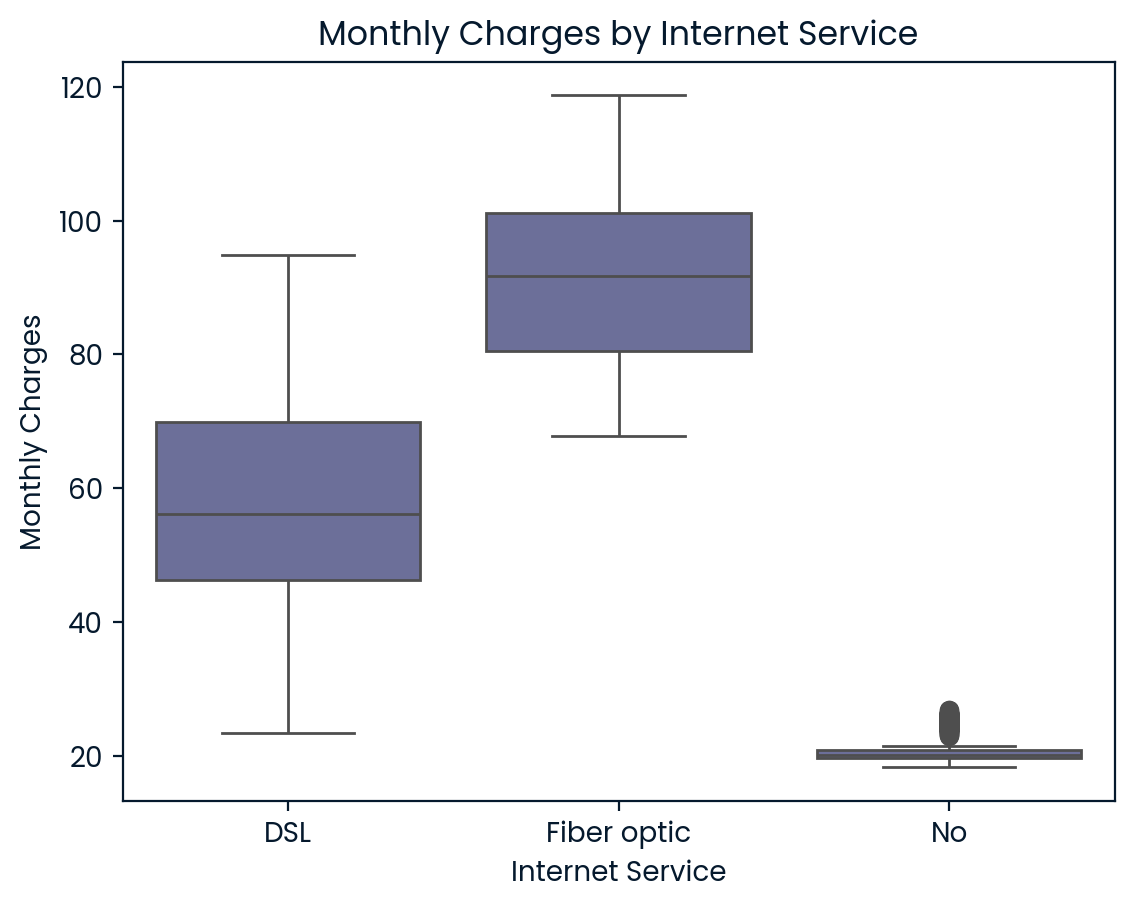

In [19]:
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges")

plt.title("Monthly Charges by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Monthly Charges")
plt.show()

Fiber customers pay roughly $33 more per month on average than DSL customers and 70USD more than No service customers.

That's a substantial difference.

And notice something useful: the mean and median for fiber are almost identical ($91.50 vs $91.68). That suggests the typical fiber customer is indeed around the $90/month level, rather than the mean being driven primarily by a few extreme customers.

## Our next test

Let's examine MonthlyCharges and Churn separately for each InternetService.

In other words:

Within DSL customers, does higher monthly cost correspond to higher churn?

Within fiber customers, does higher monthly cost correspond to higher churn?

This will help us understand whether the relationship between charges and churn is consistent across internet services.

In [20]:
print(df.groupby(["InternetService", "Churn"])["MonthlyCharges"].mean())
print(df.groupby(["InternetService", "Churn"])["MonthlyCharges"].median())

InternetService  Churn
DSL              No       60.212105
                 Yes      49.083224
Fiber optic      No       93.932379
                 Yes      88.126484
No               No       21.136058
                 Yes      20.368142
Name: MonthlyCharges, dtype: float64
InternetService  Churn
DSL              No       59.75
                 Yes      49.25
Fiber optic      No       94.80
                 Yes      87.55
No               No       20.15
                 Yes      20.00
Name: MonthlyCharges, dtype: float64


Our previous hypothesis was: Higher MonthlyCharges → higher churn

But when we look within each InternetService group, we see the opposite pattern: the churned customers actually have lower average MonthlyCharges.

## Why might this happen?

Consider the composition of the customer population.

Fiber customers have much higher charges overall, and fiber customers also have much higher churn.

So when we compare all churners against all non-churners, the composition of the groups matters.

This is related to a statistical phenomenon called confounding (and, in some settings, patterns like Simpson's paradox).

## 4. What can we conclude?

We can confidently say:

Supported by our EDA

InternetService is strongly associated with MonthlyCharges : Fiber customers have substantially higher charges than DSL customers.

InternetService is strongly associated with Churn: Fiber customers have substantially higher churn.

Within each InternetService category, churned customers have slightly lower average MonthlyCharges than customers who stayed.

Therefore, we should not simply tell the client: "Customers churn because their monthly charges are high."

Our deeper analysis doesn't support that simple explanation.

initial thought: Fiber → expensive → churn

The data now suggests: Fiber → expensive and high churn

but: Within fiber customers, those who churn don't have the highest charges on average.

So there are probably **other characteristics** interacting with these variables.

## Our next test

Let's examine tenure and Churn separately for each InternetService.

the next variable we should investigate is tenure.

**We already know**: Churned customers have much lower tenure overall.

**And we know**: Fiber customers have high churn.

**So let's ask**: Does tenure differ between churned and non-churned customers within each InternetService category?

In [21]:
print(df.groupby(["InternetService", "Churn"])["tenure"].mean())
print(df.groupby(["InternetService", "Churn"])["tenure"].median())

InternetService  Churn
DSL              No       37.198777
                 Yes      14.111111
Fiber optic      No       42.089494
                 Yes      20.196608
No               No       32.331210
                 Yes       8.238938
Name: tenure, dtype: float64
InternetService  Churn
DSL              No       37.0
                 Yes       5.0
Fiber optic      No       45.0
                 Yes      13.0
No               No       28.0
                 Yes       1.0
Name: tenure, dtype: float64


So within every InternetService category, churned customers have substantially shorter tenure.

2. The important discovery

Our hypothesis was:

"**Fiber customers who churn should have lower tenure than fiber customers who stay**."

that's correct :

Fiber:

Stayed       → median 45 months while Churned      → median 13 months

That's a huge difference.

But look at something even more interesting:

DSL:

Stayed       → median 37 months , Churned      → median 5 months

No internet:

Stayed       → median 28 months , Churned      → median 1 month

So the relationship between short tenure and churn isn't unique to fiber.

Look at the median tenure of churned customers:

DSL            5 months , Fiber optic   13 months , No internet    1 month

That suggests something worth investigating:

**Customers who churn may often leave relatively early in their relationship with the company.**

And this could have a very practical business implication.

Imagine you're the telecom company.

Instead of treating every customer equally, you might want to identify:

New customers who show characteristics associated with high churn risk.

We've investigated:

**Contract
,tenure
,MonthlyCharges
,InternetService**

And we've started examining interactions between them.

There are still several important categorical variables we haven't explored.

Some particularly interesting ones are:

**PaymentMethod** :Could the way customers pay be associated with churn?

**TechSupport** : Does having technical support correspond to different churn rates?

**OnlineSecurity** : Same question.

**SeniorCitizen** : Does churn differ between these groups?

Partner / Dependents

Do customers with family-related characteristics have different churn patterns?

🎯 Our next EDA question

I'd like to investigate **PaymentMethod** next because it's a very natural business question we'll folow the same workflow : **Hypothesis → test → unexpected result (if any) → investigate → refine our understanding.**

**Hypothesis** : Which payment method have the highest churn ?

In [22]:
print(df["PaymentMethod"].value_counts())

print(pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100)

Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: PaymentMethod, dtype: int64
Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


Electronic check has a churn rate of 45.29%, much higher than the other payment methods.

Notice the gap: 
**Mailed check**            19.1%
**Bank transfer**           16.7%
**Credit card**             15.2%

Electronic check has a churn rate almost three times that of credit-card automatic payment.

That's a potentially powerful predictive feature.

But again, we should not immediately conclude: **"Electronic checks cause customers to churn."**

There could be another variable behind this relationship. For example, perhaps electronic-check customers tend to be:

- newer customers,
- month-to-month customers,
- customers paying higher charges,
- or customers with particular service combinations.

And you may notice something important: we've already learned that month-to-month customers have very high churn.

So our next question should be: **Are electronic-check customers disproportionately month-to-month?**

In [23]:
print(pd.crosstab(
    df["PaymentMethod"],
    df["Contract"],
    normalize="index"
) * 100)

Contract                   Month-to-month   One year   Two year
PaymentMethod                                                  
Bank transfer (automatic)       38.147668  25.323834  36.528497
Credit card (automatic)         35.676741  26.149803  38.173456
Electronic check                78.224101  14.672304   7.103594
Mailed check                    55.397022  20.905707  23.697270


The difference is huge.

**78.2%** of electronic-check customers are month-to-month.

Compare that with:

- Bank transfer → 38.1%
- Credit card → 35.7%
- Mailed check → 55.4%

So our hypothesis was strongly supported.

So we've uncovered a very interesting chain:

Electronic check

       │
       ▼
78.2% month-to-month

       │
       ▼
Month-to-month

       │
       ▼
42.7% churn

This gives us a plausible explanation for part of the very high churn rate associated with electronic checks.

But—and this is important—we still don't know whether contract type fully explains the relationship.

## **Like we did with Fiber**

We asked: **"Does fiber still have higher churn when we compare customers with the same contract?"**

We should do the same thing here.

Our question becomes: **Within each contract type, do electronic-check customers still have higher churn than customers using other payment methods?**

In [24]:
print(pd.crosstab(
    [df["PaymentMethod"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100)

Churn                                            No        Yes
PaymentMethod             Contract                            
Bank transfer (automatic) Month-to-month  65.874363  34.125637
                          One year        90.281330   9.718670
                          Two year        96.631206   3.368794
Credit card (automatic)   Month-to-month  67.219153  32.780847
                          One year        89.698492  10.301508
                          Two year        97.762478   2.237522
Electronic check          Month-to-month  46.270270  53.729730
                          One year        81.556196  18.443804
                          Two year        92.261905   7.738095
Mailed check              Month-to-month  68.421053  31.578947
                          One year        93.175074   6.824926
                          Two year        99.214660   0.785340


The pattern is consistent

Month-to-month: Electronic check → 53.7% while the others are around 31.6–34.1%.

One year: Electronic check → 18.4% while the others are around 6.8–10.3%.

Two year: Electronic check → 7.7% while the others are around 0.8–3.4%.

So our answer is:

**Yes. Electronic-check customers still have higher churn within every contract category.**

after comparing customers with the same contract type, electronic-check customers still have higher churn.

Therefore:

The relationship between PaymentMethod and Churn is not completely explained by the difference in contract types.

That's a much stronger analytical conclusion.

At this stage, we should still avoid saying:

**"Electronic checks cause customers to churn."**

Our analysis is observational.

The safer statement is: PaymentMethod is strongly associated with Churn, and the association remains after stratifying by Contract.

There may be other variables behind the relationship.

For example, electronic-check customers might also differ in:

- tenure
- InternetService
- MonthlyCharges
- TechSupport
- OnlineSecurity
- SeniorCitizen
- etc.

And those variables could themselves be related to churn.

So far we've investigated:

- Contract
- Tenure
- MonthlyCharges
- InternetService
- PaymentMethod

And we've started looking at interactions between them.

I'd like to investigate **TechSupport** next because it has an interesting business interpretation: **Does having technical support appear to be associated with lower churn?**

In [25]:
print(pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100 )

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


Customers with TechSupport = Yes have a much lower observed churn rate (15.17%) than customers with TechSupport = No (41.64%).

There's an important detail, though:

What about "No internet service"?  Its churn rate is only 7.40%, even lower than customers with TechSupport.

But this isn't really surprising: customers with No internet service don't actually have the possibility of having technical support for internet service.

**Could another variable be behind this relationship?**

For example, perhaps customers with TechSupport are also more likely to have longer contracts, and contract type is actually responsible for some of the difference.

So before moving on, I'd investigate one particularly important relationship:

**TechSupport → Contract → Churn**

### Hypothesis : **customers with TechSupport are more likely to have one-year/two-year contracts than month-to-month contracts**

In [26]:
print(pd.crosstab(
    df["TechSupport"],
    df["Contract"],
    normalize="index"
) * 100)

Contract             Month-to-month   One year   Two year
TechSupport                                              
No                        77.166715  16.038007   6.795278
No internet service       34.338139  23.853211  41.808650
Yes                       32.827789  27.005871  40.166341


What does this tell us?

the prediction was correct:

Customers without TechSupport are overwhelmingly month-to-month: 77.17%.
Customers with TechSupport are much less likely to be month-to-month: 32.83%.
TechSupport customers are particularly concentrated in two-year contracts: 40.17%.

So we have a plausible chain:

TechSupport → Contract type → Churn

But now comes the important part of our investigation:

Does Contract actually explain the lower churn among TechSupport customers?

We need to do exactly what we did with PaymentMethod.

In [27]:
print(pd.crosstab(
    [df["TechSupport"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100)

Churn                                      No        Yes
TechSupport         Contract                            
No                  Month-to-month  49.626866  50.373134
                    One year        85.278276  14.721724
                    Two year        94.067797   5.932203
No internet service Month-to-month  81.106870  18.893130
                    One year        97.527473   2.472527
                    Two year        99.216301   0.783699
Yes                 Month-to-month  69.299553  30.700447
                    One year        86.413043  13.586957
                    Two year        96.467722   3.532278


What have we learned?

Our original observation was:

TechSupport → lower churn

We then discovered:

TechSupport → Contract

because TechSupport customers are much more likely to have longer contracts.

So Contract does explain part of the overall difference.

But after controlling for Contract, we still see:

**TechSupport = Yes → lower churn within each contract category.**

Therefore:

_Contract does NOT completely explain the TechSupport–Churn relationship._

That's exactly the type of reasoning we wanted to learn.

One particularly interesting finding is the month-to-month group:

In [28]:
print(pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100)

Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


Among customers with internet service:

OnlineSecurity = No → 41.77% churn
OnlineSecurity = Yes → 14.61% churn

That's a difference of about 27 percentage points, which is substantial.

**But now we should apply the same reasoning we've learned**

We shouldn't stop at : OnlineSecurity → lower churn.

We should ask : Could Contract explain part of this relationship?

For example, perhaps customers with OnlineSecurity are much more likely to have one-year or two-year contracts, and we've already established that longer contracts have much lower churn.

So let's investigate : OnlineSecurity → Contract → Churn

In [29]:
print(pd.crosstab(
    df["OnlineSecurity"],
    df["Contract"],
    normalize="index"
) * 100)

Contract             Month-to-month   One year   Two year
OnlineSecurity                                           
No                        75.214408  15.923385   8.862207
No internet service       34.338139  23.853211  41.808650
Yes                       35.661218  27.340267  36.998514


Customers with OnlineSecurity = **No** are overwhelmingly month-to-month **(75.21%**), while customers with OnlineSecurity = **Yes** are much more distributed toward longer contracts.

This means Contract is a plausible explanation for part of the OnlineSecurity–Churn relationship.

But we haven't answered the key question yet:

Does OnlineSecurity still have an association with churn when we compare customers within the same contract type?

In [30]:
print(pd.crosstab(
    [df["OnlineSecurity"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100)

Churn                                      No        Yes
OnlineSecurity      Contract                            
No                  Month-to-month  48.954770  51.045230
                    One year        82.585278  17.414722
                    Two year        93.225806   6.774194
No internet service Month-to-month  81.106870  18.893130
                    One year        97.527473   2.472527
                    Two year        99.216301   0.783699
Yes                 Month-to-month  70.416667  29.583333
                    One year        89.130435  10.869565
                    Two year        97.054886   2.945114


Among customers with internet service, OnlineSecurity = Yes is associated with lower churn than OnlineSecurity = No within each contract category. Since the association persists after stratifying by Contract, Contract does not completely explain the observed relationship between OnlineSecurity and churn.

That's a very solid EDA conclusion.

And notice something deeper

Look at what happened:

Before controlling for Contract:

OnlineSecurity Yes → 14.61% churn
OnlineSecurity No → 41.77% churn

Huge difference.

After controlling for Contract:

Month-to-month: 29.58% vs 51.05%
One-year: 10.87% vs 17.41%
Two-year: 2.95% vs 6.77%

The difference gets smaller, but it doesn't disappear.

That tells us something useful:

Contract explains part of the original relationship, but not all of it.

Our next step: other service-related variables

The natural next candidates are:

OnlineBackup → Churn
DeviceProtection → Churn
StreamingTV → Churn
StreamingMovies → Churn

But we don't need to investigate all of them with the same depth. First, simply test their relationship with churn.

Let's start with OnlineBackup.
Before running anything, make your hypothesis:

Do you expect customers with OnlineBackup = Yes to have a lower or higher churn rate than customers with OnlineBackup = No?

In [31]:
print(pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100)

Churn                       No        Yes
OnlineBackup                             
No                   60.071244  39.928756
No internet service  92.595020   7.404980
Yes                  78.468506  21.531494


- OnlineBackup = No → 39.93% churn
- OnlineBackup = Yes → 21.53% churn

So there's about an 18.4 percentage-point difference.

Your reasoning was therefore reasonable: customers with OnlineBackup are indeed observed to churn less.

But let's notice something

Compare the strength of the relationships we've found:

- TechSupport: 41.64% → 15.17%
- OnlineSecurity: 41.77% → 14.61%
- OnlineBackup: 39.93% → 21.53%

So OnlineBackup has a noticeable relationship, but the difference is smaller.

And now we apply our EDA pattern again:

Could Contract explain part of this relationship?

In [32]:
print(pd.crosstab(
    df["OnlineBackup"],
    df["Contract"],
    normalize="index"
) * 100)

Contract             Month-to-month   One year   Two year
OnlineBackup                                             
No                        74.093264  15.770725  10.136010
No internet service       34.338139  23.853211  41.808650
Yes                       43.762865  25.607246  30.629889


In [33]:
print(pd.crosstab(
    [df["OnlineBackup"], df["Contract"]],
    df["Churn"],
    normalize="index"
) * 100)

Churn                                      No        Yes
OnlineBackup        Contract                            
No                  Month-to-month  49.694056  50.305944
                    One year        86.652977  13.347023
                    Two year        94.568690   5.431310
No internet service Month-to-month  81.106870  18.893130
                    One year        97.527473   2.472527
                    Two year        99.216301   0.783699
Yes                 Month-to-month  61.900282  38.099718
                    One year        85.209003  14.790997
                    Two year        96.505376   3.494624


What does this tell us?

Your interpretation should be a little more careful here.

- Month-to-month: OnlineBackup = Yes has substantially lower churn: 38.10% vs 50.31%.
- One-year: the pattern actually reverses slightly: 14.79% vs 13.35%.
- Two-year: OnlineBackup = Yes again has lower churn: 3.49% vs 5.43%.

So unlike TechSupport and OnlineSecurity, the relationship doesn't consistently point in the same direction across every contract category.

Therefore

We can say:

OnlineBackup is associated with lower overall churn, but the relationship is partly related to Contract. After stratifying by Contract, the association is not consistent across all contract categories.

This is actually a very valuable EDA finding.

It tells us we shouldn't simply say:

❌ "OnlineBackup customers are less likely to churn."

A better statement is:

✅ "Customers with OnlineBackup have a lower overall observed churn rate, but this difference varies by contract type."

- OnlineBackup → Churn = interesting
- OnlineBackup → Contract = strong relationship
- Contract + OnlineBackup → Churn = relationship varies by contract


Next, I'd move to **DeviceProtection** and use the same first-level test:

In [34]:
print(pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100)

Churn                       No        Yes
DeviceProtection                         
No                   60.872375  39.127625
No internet service  92.595020   7.404980
Yes                  77.497936  22.502064


result is similar to OnlineBackup:

- OnlineBackup = No → 39.93%
- OnlineBackup = Yes → 21.53%
- DeviceProtection = No → 39.13%
- DeviceProtection = Yes → 22.50%

This suggests that these additional services are associated with lower churn.

But notice something important

We're seeing a pattern:

- TechSupport = Yes → 15.17%
- OnlineSecurity = Yes → 14.61%
- OnlineBackup = Yes → 21.53%
- DeviceProtection = Yes → 22.50%

It would be tempting to conclude:

"Additional services cause customers to stay."

But we shouldn't do that yet.

These services may be correlated with other characteristics such as:

- Contract
- Tenure
- InternetService
- MonthlyCharges
- Customer segment

For example, customers with several additional services might simply be more established customers with longer contracts.

And this is exactly where we're reaching the point where manually checking every combination becomes inefficient.

let's finish the first-level EDA with the remaining service variables:

StreamingTV → Churn

and

StreamingMovies → Churn

Then we'll step back and summarize the entire EDA.

In [35]:
print(pd.crosstab(df["StreamingTV"], df["Churn"], normalize="index") * 100)

Churn                       No        Yes
StreamingTV                              
No                   66.476868  33.523132
No internet service  92.595020   7.404980
Yes                  69.929812  30.070188


Among customers with internet service:

- StreamingTV = No → 33.52% churn
- StreamingTV = Yes → 30.07% churn

So the difference is only about 3.45 percentage points.

Compare that with what we found:

- TechSupport: 41.64% → 15.17%
- OnlineSecurity: 41.77% → 14.61%
- OnlineBackup: 39.93% → 21.53%
- DeviceProtection: 39.13% → 22.50%
- StreamingTV: 33.52% → 30.07%
What should we do with this?

This is a good example of prioritizing meaningful relationships.

StreamingTV has some association with churn, but the difference is relatively small. I wouldn't spend time doing:

StreamingTV → Contract → Churn
StreamingTV → Tenure → Churn
StreamingTV → MonthlyCharges → Churn
...

at this stage.

We can simply record : **StreamingTV has a relatively weak relationship with churn in this dataset**

Let's test the final related service:

In [36]:
print(pd.crosstab( df["StreamingMovies"], df["Churn"], normalize="index" ) * 100)

Churn                       No        Yes
StreamingMovies                          
No                   66.319569  33.680431
No internet service  92.595020   7.404980
Yes                  70.058565  29.941435


For StreamingMovies:

- No → 33.68% churn
- Yes → 29.94% churn
Difference ≈ 3.74 percentage points

And that's very similar to StreamingTV:

So we can treat both as relatively weak individual relationships with churn compared with variables like Contract, Tenure, TechSupport, and OnlineSecurity.

In [37]:
print(df.groupby("Churn")["TotalCharges"].mean())
print(df.groupby("Churn")["TotalCharges"].median())

Churn
No     2549.911442
Yes    1531.796094
Name: TotalCharges, dtype: float64
Churn
No     1679.525
Yes     703.550
Name: TotalCharges, dtype: float64


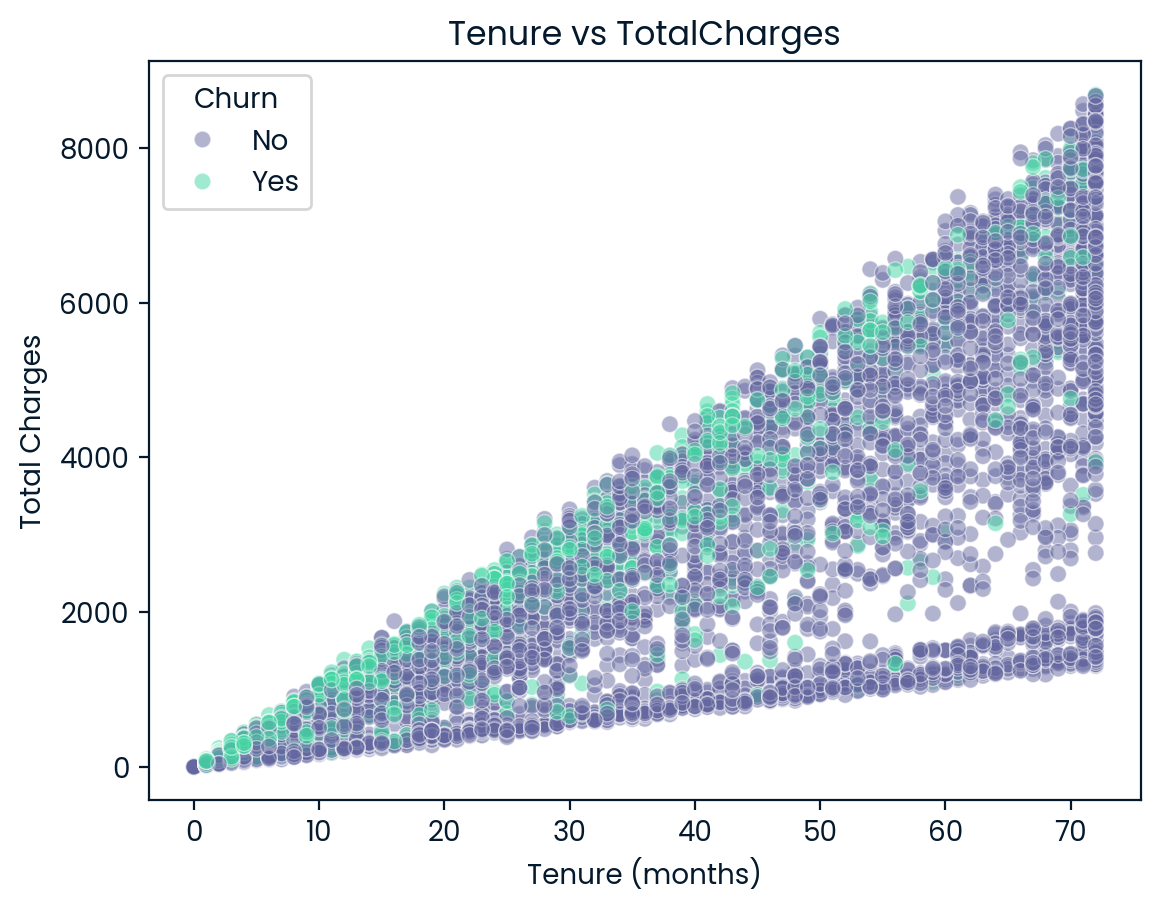

In [38]:
sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges",
    hue="Churn",
    alpha=0.5
)

plt.title("Tenure vs TotalCharges")
plt.xlabel("Tenure (months)")
plt.ylabel("Total Charges")
plt.show()

What we can observe

There is a strong positive relationship between tenure and TotalCharges:

As tenure increases, TotalCharges generally increases.

You can see the points forming a broad upward pattern from the lower-left toward the upper-right.

There is another interesting observation

The Churn = Yes points are concentrated much more heavily toward the lower-tenure / lower-TotalCharges region.

This is consistent with what we already found:

Lower tenure → higher churn  and  Lower tenure → lower TotalCharges

So we need to be careful not to interpret : ❌ TotalCharges is low → customer churns.

A more appropriate interpretation is:

✅ Lower TotalCharges is associated with churn, but much of this relationship may simply reflect the customer's tenure.

This raises an important ML question

If tenure and TotalCharges contain very similar information, should we keep both in our model?

In [39]:
df[["tenure", "TotalCharges"]].corr()

,tenure,TotalCharges
tenure,1.000000,0.826178
TotalCharges,0.826178,1.000000


0.826 → strong positive relationship

In our dataset, customers with greater tenure generally have greater TotalCharges.

But here's the important ML lesson 0.826 does NOT mean we must remove one of the variables.

It means they contain substantial overlapping information.

Think about the difference:

- tenure = how long the customer has been with the company.
- TotalCharges = how much the customer has accumulated in charges.

They're different concepts, but naturally related.

Should we keep both?

For our project, I would initially keep both.

Why?

We're going to compare different models, and some models handle correlated predictors well. We can later evaluate whether removing TotalCharges changes validation performance.

This gives us a nice practical experiment:

Model A : tenure + TotalCharges + other features

versus

Model B : tenure + other features

Then compare their validation performance.

## Where we are now

### We've essentially completed the main EDA.

So we're at an important transition:

**EDA** → Feature Engineering → Train/Validation/Test → Preprocessing Pipeline → Baseline Model

Now we move from EDA → preparing the data for machine learning.

I suggest we do this in a disciplined sequence:

## Step 1 — Finalize the feature roles

we already know target : **churn** , drop: **CustomerId** , numerical variables : (**tenure ,MonthlyCharges, TotalCharges**) , Categorical :Everything else, with **SeniorCitizen** treated conceptually as a categorical/binary variable. and there still no null values 

## Step 2 — Feature engineering — what's coming next
### Feature 1 — Average monthly charge over customer lifetime
AvgMonthlyCharge = tenure / TotalCharges
	
This answers a slightly different question:

"On average, how much has this customer paid per month during their relationship with the company?"

That's potentially useful because **MonthlyCharges** represents the current monthly charge, whereas this engineered feature represents the customer's historical average.

we have to handle the situation when tenure = 0 (division by zero problem) customers with 0 months would have o total charges 



In [40]:
df["AvgMonthlyCharge"] = np.where(
    df["tenure"] > 0,
    df["TotalCharges"] / df["tenure"],
    0
)

However, there's an important nuance: 0 is not literally an observed average monthly charge. In a more sophisticated project, we could instead use NaN and let the preprocessing pipeline impute it. For our first portfolio project, the explicit approach above is easy to understand and defensible.

Then we'll ask the important question:

Does this engineered feature (**AvgMonthlyCharge**)actually contain useful information, or is it mostly redundant with MonthlyCharges and TotalCharges?

In [41]:
print(df[["tenure", "MonthlyCharges", "TotalCharges", "AvgMonthlyCharge"]].head(10))

   tenure  MonthlyCharges  TotalCharges  AvgMonthlyCharge
0       1           29.85         29.85         29.850000
1      34           56.95       1889.50         55.573529
2       2           53.85        108.15         54.075000
3      45           42.30       1840.75         40.905556
4       2           70.70        151.65         75.825000
5       8           99.65        820.50        102.562500
6      22           89.10       1949.40         88.609091
7      10           29.75        301.90         30.190000
8      28          104.80       3046.05        108.787500
9      62           56.15       3487.95         56.257258


we remark MonthlyCharges and AvgMonthlyCharge are often fairly close This means they're correlated that what we will test .

We'll determine whether AvgMonthlyCharge actually adds a new dimension of information or is mostly a transformation of variables we already have.

This is exactly what good feature engineering looks like:

**Create → inspect → test usefulness → keep or discard.**

In [42]:
print(df[["MonthlyCharges", "AvgMonthlyCharge"]].corr())

print(df[["TotalCharges", "AvgMonthlyCharge"]].corr())

                  MonthlyCharges  AvgMonthlyCharge
MonthlyCharges          1.000000          0.994355
AvgMonthlyCharge        0.994355          1.000000
                  TotalCharges  AvgMonthlyCharge
TotalCharges          1.000000          0.651435
AvgMonthlyCharge      0.651435          1.000000


**What does 0.994 tell us?**

That's an extremely strong correlation.

It means **AvgMonthlyCharge** contains almost the same information as **MonthlyCharges**.

So we've essentially created a feature that is almost a duplicate of **MonthlyCharges**.

Should we keep it? For our project, I'd remove it.

Why?

Because our goal isn't to create as many features as possible. It's to create useful information.

AvgMonthlyCharge doesn't appear to provide much new information beyond MonthlyCharges.

And this is an important professional lesson:

Feature engineering ≠ creating more features.

It's about creating better or more informative features.

In [43]:
df.drop(columns=["AvgMonthlyCharge"], inplace=True)

### Feature 2 — The number of additional services the customer has.

We have several service variables:

- OnlineSecurity
- OnlineBackup
- DeviceProtection
- TechSupport
- StreamingTV
- StreamingMovies

We've already noticed that some of these are associated with churn.

Instead of treating each service completely independently, we could create : **NumAdditionalServices**

contains the number of services having "yes" 

In [44]:
#create a liste of available services
service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]
#create a new feature conatins the number of services for every customer
df["NumAdditionalServices"] = (
    df[service_cols] == "Yes"
).sum(axis=1)

df[["NumAdditionalServices"] + service_cols].head(10)

,NumAdditionalServices,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,No,Yes,No,No,No,No
1,2,Yes,No,Yes,No,No,No
2,2,Yes,Yes,No,No,No,No
3,3,Yes,No,Yes,Yes,No,No
4,0,No,No,No,No,No,No
5,3,No,No,Yes,No,Yes,Yes
6,2,No,Yes,No,No,Yes,No
7,1,Yes,No,No,No,No,No
8,4,No,No,Yes,Yes,Yes,Yes
9,2,Yes,Yes,No,No,No,No


In [45]:
print(df["NumAdditionalServices"].value_counts().sort_index())

print(pd.crosstab(
    df["NumAdditionalServices"],
    df["Churn"],
    normalize="index"
) * 100)

0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: NumAdditionalServices, dtype: int64
Churn                         No        Yes
NumAdditionalServices                      
0                      78.593961  21.406039
1                      54.244306  45.755694
2                      64.181994  35.818006
3                      72.629696  27.370304
4                      77.699531  22.300469
5                      87.565674  12.434326
6                      94.718310   5.281690


The biggest churn rate is actually at 1 service: 45.76%. Then, after 1 service, churn generally decreases as the number of services increases.
So there appears to be an interesting pattern:
1 service → very high churn
then:
2 → 3 → 4 → 5 → 6 services → progressively lower churn
But there's an important issue with the 0 group
Remember that our feature counts only "Yes".
Therefore, NumAdditionalServices = 0 includes customers who have:
- **OnlineSecurity** = No
- **OnlineBackup** = No
- **DeviceProtection** = No
- **TechSupport** = No
- **StreamingTV** = No
- **StreamingMovies** = No

including customers with **No internet service**.
We already know that No internet service customers have only 7.40% churn. So the 21.41% for the 0 group is mixing different types of customers.
That's why I wouldn't interpret: "0 services has lower churn than 1 service"

**NumAdditionalServices** appears potentially useful because there is a substantial difference in churn rates across the groups.
But we should not assume the relationship is causal or even purely due to the number of services. For example, customers with 5–6 services might also tend to have:
- longer tenure
- longer contracts
- particular internet-service types
- different payment methods
So this feature may be capturing a broader customer profile.
I would keep this feature for now.
Unlike our **AvgMonthlyCharge**, which had a correlation of 0.994 with **MonthlyCharges** and was essentially redundant, **NumAdditionalServices** represents a genuinely different concept.

### Feature 3 — create IsNewCustomer segmenting customers's tenure.

We already discovered that tenure is strongly associated with churn, so instead of asking the model only about exact tenure, we can create a business-oriented indicator such as:
tenure <= 12 months → **IsNewCustomer** = 1
tenure > 12 months  → **IsNewCustomer** = 0

But before creating an arbitrary threshold, we should first examine how churn changes across tenure ranges. That will let the data help us choose a meaningful threshold rather than inventing one.

In [46]:
bins = [0, 6, 12, 24, 36, 48, 60, 72]
labels = [
    "0-6",
    "7-12",
    "13-24",
    "25-36",
    "37-48",
    "49-60",
    "61-72"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# calculate the churn rate
print(pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100)

#check how many customers are in each group
print(df["TenureGroup"].value_counts().sort_index())

Churn               No        Yes
TenureGroup                      
0-6          47.062795  52.937205
7-12         64.113475  35.886525
13-24        71.289062  28.710938
25-36        78.365385  21.634615
37-48        80.971129  19.028871
49-60        85.576923  14.423077
61-72        93.390192   6.609808
0-6      1481
7-12      705
13-24    1024
25-36     832
37-48     762
49-60     832
61-72    1407
Name: TenureGroup, dtype: int64


There is a very clear pattern: The newer the customer, the higher the observed churn rate.

And notice how dramatic the first group is: 0–6 months → 52.94% churn
compared with: 61–72 months → 6.61% churn , That's a very strong relationship.

**Why 12 months?**
Because the first year is clearly a high-churn period:
- 0–6 → 52.94%
- 7–12 → 35.89%
After 12 months, churn continues to decline, but the first-year period is particularly important.

In [47]:
df["IsNewCustomer"] = (df["tenure"] <= 12).astype(int)
print(pd.crosstab(
    df["IsNewCustomer"],
    df["Churn"],
    normalize="index"
) * 100)

Churn                 No        Yes
IsNewCustomer                      
0              82.870084  17.129916
1              52.561757  47.438243


Why? **IsNewCustomer** is derived from tenure, so it contains overlapping information. But it also expresses a specific business concept that could be useful : _is this customer in his first year ?_, especially for a linear model.
Later, during model comparison, we can test whether it actually improves validation performance.
That's the correct mindset: Don't decide that a feature is useful just because the EDA looks good. Let validation performance ultimately decide.

Let's finalize the feature set before moving to train/test splitting.
We've experimented with several engineered features, and now we need to make deliberate decisions.
1. Features we're keeping
Original features
We'll keep:
### Numerical
**tenure
MonthlyCharges
TotalCharges**

### Categorical
**gender
SeniorCitizen
Partner
Dependents
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod**

**SeniorCitizen** is stored as 0/1, but conceptually we'll treat it as a binary categorical feature during preprocessing.

### Engineered features
**NumAdditionalServices** ✅
Keep it because it represents a meaningful concept:
How many additional services does the customer have?

We saw a substantial difference in churn across service-count groups.
**IsNewCustomer** ✅
Keep it because it represents a clear business concept:
Is this customer in their first year?

We found:
0–6 months   → 52.94% churn
7–12 months  → 35.89%
13–24 months → 28.71%
...

So this feature has a reasonable business justification.
2. Features we're removing
**customerID** ❌
It's an identifier, not a meaningful predictive feature.

AvgMonthlyCharge ❌
We tested it and found : **MonthlyCharges** ↔ **AvgMonthlyCharge** = 0.994 So it is almost a duplicate of MonthlyCharges.

TenureGroup ❌
We created it to investigate the relationship between tenure and churn.
It served its purpose.

In [48]:
df.drop(columns=["TenureGroup"], inplace=True)

### One important point
We're not claiming these are the final optimal features.
They're our candidate feature set.
Later, model validation may show that some features add little value. That's normal in professional ML work.
The workflow is: **EDA → engineer candidates** → build model → validate → refine

rather than: EDA → decide forever which features are good.


### Then comes the next major step

In [49]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

print(X.shape)
print(y.shape)

print(df.shape)
print(df.columns.tolist())

print(X.columns.tolist())

(7043, 21)
(7043,)
(7043, 23)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn', 'NumAdditionalServices', 'IsNewCustomer']
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'NumAdditionalServices', 'IsNewCustomer']


## Step 3 — Train/test split

Now we should not preprocess the entire dataset before splitting.
Let's first create our training and test sets:

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 21)
X_test: (1409, 21)
y_train: (5634,)
y_test: (1409,)


**Why stratify=y?**

Remember our target distribution:
- No: ~73.5%
- Yes: ~26.5%
We want the training and test sets to maintain approximately the same proportion of churned customers.
Without stratify, we could accidentally get, for example:
- Training: 75% No / 25% Yes
- Test:     68% No / 32% Yes

Because from this point forward, we want the test set to behave like completely unseen data.

Then we'll do the important professional part
After the split, we'll identify:
numerical_features and categorical_features


and build a ColumnTransformer + Pipeline.
Something conceptually like:
                    X_train
                       │
             ┌─────────┴─────────┐
             │                   │
       Numerical             Categorical
             │                   │
      StandardScaler       OneHotEncoder
             │                   │
             └─────────┬─────────┘
                       │
                 ML algorithm
                       │
                    Model


After the split, let's explicitly define our feature types numerical and categorical:                    

In [51]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumAdditionalServices"
]

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "IsNewCustomer"
]

print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))
print("Total:", len(numerical_features) + len(categorical_features))

print("\nMissing from lists:")
print(set(X.columns) - set(numerical_features) - set(categorical_features))

Numerical: 4
Categorical: 17
Total: 21

Missing from lists:
set()


We now have:

Training set: 5,634 customers
 Test set:      1,409 customers

Features:      21
 **Numerical**:      4
 **Categorical**:   17

So now we reach an important part of the project: **preprocessing**.

### Build the **preprocessing** pipeline

We have two different types of features, and they need different treatments.

Numerical features

For these, we'll use: **StandardScaler**()


Categorical features

We cannot directly give strings such as : 
"Month-to-month"
 "One year"
 "Two year"

to most ML algorithms.

So we'll use: **OneHotEncoder**()

In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)
# used for test we shall remove because the pipeline will do the transformation of numerical and categorical features
#X_train_processed = preprocessor.fit_transform(X_train)
#X_test_processed = preprocessor.transform(X_test)


### **handle_unknown="ignore**"?
This small parameter is very important for deployment.
Suppose our training data contains:
**Contract**:
Month-to-month
One year
Two year

Later, when our model is deployed, perhaps a new category appears: **Contract** = "Three year"

If we didn't specify : handle_unknown="ignore"


the encoder could throw an error.

### Fit the preprocessor only on training data
Now comes an important concept.
We have: **X_train** **X_test** 

Training data : **fit_transform**() means: FIT + TRANSFORM

The preprocessor learns things such as:
- numerical means
- numerical standard deviations
- categorical levels
from X_train only.

Test data  : **transform**()


means: Use what was learned from the training set to transform the test set.

It does not learn anything from the test set (avoid data leakage).

## Step 4 — Modeling
### ready for our first model
But I don't want us to immediately jump to Random Forest or GridSearchCV.
We're going to establish a baseline model first.
For this classification problem, a very good baseline is: **Logistic Regression**

Why? 
Because it's:
- relatively simple
- fast
- interpretable
- a strong baseline for binary classification
- particularly useful for comparing more complex models later

Our workflow will become: Preprocessed data -> Logistic Regression ->  Baseline predictions -> Evaluate ->  Random Forest -> Compare -> Tune the best candidates

And remember our EDA finding : Only about 26.5% of customers churn.

Therefore, we won't judge the model using accuracy alone.
We'll examine:
- confusion matrix
- precision
- recall
- F1-score
- ROC-AUC
- accuracy
The confusion matrix will be particularly useful because we'll be able to see:
                 Predicted
                 No     Yes
Actual No       TN      FP
Actual Yes      FN      TP

For a churn problem, **false negatives** are especially interesting: Customers who actually churn but whom our model predicts will stay.

### One more thing before training
Rather than using the processed matrices manually, I suggest that we now build a proper: **Pipeline**


containing: Preprocessor ->  Logistic Regression

This will make the workflow safer and will become extremely useful when we reach cross-validation and GridSearchCV.

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

logistic_pipeline.fit(X_train, y_train)

y_pred = logistic_pipeline.predict(X_test)
y_proba = logistic_pipeline.predict_proba(X_test)[:, 1]



We already had the **preprocessor** (see code above) .Now we'll attach Logistic Regression to it.

from now on, instead of manually  **fit_transform** and **transform** features we'll give the pipeline (**logistic_pipeline.fit()**) the original **X_train**, and it will automatically:
1. identify numerical/categorical columns
2. scale numerical features
3. one-hot encode categorical features
4. train the logistic regression model

The distinction **between** predict() and **predict_proba**() is important.

**predict()**
Returns the predicted class:
0
1
0
0
1
...

**predict_proba**()
Returns probabilities such as:
0.12
0.84
0.23
0.71
...

For example:
P(Churn = Yes) = 0.84

The probability will become important when we discuss ROC-AUC and classification thresholds.

In [54]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("ROC-AUC:", roc_auc_score(y_test, y_proba))

Accuracy: 0.8019872249822569

Confusion Matrix:
[[932 103]
 [176 198]]

Classification Report:
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1035
         Yes       0.66      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC: 0.8416595623756749


At first glance, 80.2% accuracy looks pretty good.
But the confusion matrix tells us something much more interesting.

### 2. Let's decode the confusion matrix

Let's identify the four cases :
 **TN** = 932
 **FP** = 103
 **FN** = 176
 **TP** = 198

So out of the 374 customers who actually churned (TP+FN) :
-  198 → correctly identified
-  176 → missed

That's important.
The model identifies:
\[
\frac{198}{374} \approx 52.9\%
\]
of churners.
That's exactly your:
Recall (Yes) = 0.53

### What does this mean from the business perspective?
Imagine the telecom company gives us 1,409 customers.
Among them :
 1035 → actually stayed / 
 374  → actually churned

Our model says :
 Predicted to stay:    1108 /
 Predicted to churn:   301

But among those 301 predicted churners : 
 198 → actually churned   ✅ / 
 103 → actually stayed    ❌

And among customers predicted to stay : 
 932 → actually stayed    ✅ / 
 176 → actually churned   ❌

So the biggest problem is: We are missing 176 customers who actually churn.

If the business wants to proactively contact customers at risk of leaving, those 176 missed customers are potentially very important.

### Precision vs Recall

churn class (Yes) has: 

- **Precision** = 0.66 Meaning: Of the customers we predicted would churn, 66% actually churned. That's reasonably good.
- **Recall** = 0.53 Meaning : Of all the customers who actually churned, we only detected 53%.

That's considerably weaker. So our model is relatively conservative about predicting churn.

### Why isn't accuracy telling the whole story?

Remember our EDA: No  → 73.5% Yes → 26.5%

A stupid model that predicts for everybody "No"  would already obtain approximately: 73.5% accuracy

Our model gets: 80.2%

So it is definitely learning something useful. But the real question is: How much better is it at identifying churners?

That's why we look at **recall**, **precision**, F1 and ROC-AUC.

ROC-AUC = 0.84166 is actually quite encouraging for a first baseline. ROC-AUC measures the model's ability to rank churners above non-churners across different classification thresholds. it tells us that Logistic Regression has learned a meaningful signal from the features.

If the model has reasonably strong discriminatory ability, why is churn recall only 53%?

The answer is that the default classification threshold is 0.5. [ P(Churn) >= 0.5 → Yes P(Churn) <  0.5 → No ]

"If the probability of churn is above 0.35, let's classify the customer as high-risk."

Then we'd probably catch more churners. But we'd also produce more **false positives**. And that introduces an important ML concept:

### The precision–recall trade-off

Suppose: Threshold = 0.50 We currently have approximately: **recall**    = 53%  and **precision** = 66%

If we lower the threshold: Threshold = 0.40 we'll probably get: **recall** ↑ and **precision** ↓

And if we raise it: Threshold = 0.70

we'll probably get: **recall** ↓ and **precision** ↑

So the question becomes: What is more important for our business?

- If contacting a customer costs very little but losing a customer is expensive, we might prefer higher **recall**.
- If contacting customers is expensive, we may prefer higher **precision**.

### One more interesting observation

Compare the two classes:
Customers who stay
- Precision = 0.84
- Recall    = 0.90
- F1        = 0.87

Very good.

Customers who churn
- Precision = 0.66
- Recall    = 0.53
- F1        = 0.59

Clearly harder.

This makes intuitive sense. The model has learned that identifying customers who stay is relatively easy, while identifying the relatively smaller and more heterogeneous group of customers who churn is harder.

We're establishing:
Baseline -> Accuracy ≈ 80% , ROC-AUC ≈ 0.842, Churn recall ≈ 53%

Now, when we try another model, we'll have something to compare against.

before comparing against other models We can investigate:
_Which features are pushing the model toward churn or non-churn?_

Because Logistic Regression is relatively interpretable. We can extract its **coefficients** This enable us to see whether the model has learned relationships that resemble what we discovered during **EDA**.

### First, let's understand what a coefficient means

Logistic Regression estimates the probability of: Churn = Yes using the features.

Conceptually:
\[
P(Churn=Yes)=\frac{1}{1+e^{-z}}
\]
where:
\[
z = b + w_1x_1+w_2x_2+....+w_nx_n
\]
Each feature has a coefficient \(w\).

coefficient > 0  pushes the prediction toward : Churn = Yes

coefficient < 0  pushes the prediction toward : Churn = No

And the larger the absolute value : |w|

the stronger the feature's influence within this particular model and encoding.

the coefficients correspond to 49 transformed features.

### Let's connect this to our EDA

This is the interesting part.
Remember what EDA told us?
We found: Contract
Month-to-month → high churn
Two year       → very low churn

So we might expect: Contract_Month-to-month → positive coefficient

and: Contract_Two year → negative coefficient

So we'd expect the model to find some association between these categories and churn.
But here we need to be careful.

### coefficients are not the same as EDA percentages

Suppose EDA tells us: Fiber → 41.8% churn and: DSL → 19.0%

We cannot conclude that Logistic Regression must have :  Fiber coefficient = +22.8

That's not how it works.

The coefficient represents the effect of that feature while considering the other features in the model.
That's a major difference.
EDA asks : _"What is the relationship between this variable and churn?"_

Logistic Regression asks approximately: _"After considering the other features in the model, how does this feature contribute to the log-odds of churn?"_

### coefficient magnitude

Suppose we see:
- Feature A     +1.50
- Feature B     +0.10
- Feature C     -1.20

We can generally say:
- A → strong positive influence
- C → strong negative influence
- B → weaker influence

For numerical variables, we standardized them, so their coefficients are more comparable.

For one-hot encoded categorical variables, the coefficients correspond to binary indicators.
Therefore, don't treat coefficient magnitude as a universal feature-importance score.

In [55]:
feature_names = (
    logistic_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Number of features:", len(feature_names))
print(feature_names)

coefficients = logistic_pipeline.named_steps["model"].coef_[0]

print("Number of coefficients:", len(coefficients))

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Strongest positive coefficients:")
print(
    coef_df
    .sort_values("Coefficient", ascending=False)
    .head(10)
)

print("\nStrongest negative coefficients:")
print(
    coef_df
    .sort_values("Coefficient", ascending=True)
    .head(10)
)

Number of features: 49
['num__tenure' 'num__MonthlyCharges' 'num__TotalCharges'
 'num__NumAdditionalServices' 'cat__gender_Female' 'cat__gender_Male'
 'cat__SeniorCitizen_0' 'cat__SeniorCitizen_1' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__Streaming

#### **Fiber optic is one of the strongest signals**

we have InternetService_Fiber optic : Coefficient = +0.754

That's a substantial positive coefficient.

And look at what our EDA found: Fiber optic → ~41.8% churn  ,DSL   → ~19.0%  ,No internet → ~7.4%

So there's a very nice agreement:
EDA                         Logistic Regression
      
Fiber → high churn    →     Fiber → positive coefficient

This is exactly what we wanted to see.
However, notice something interesting:
DSL coefficient = -0.581
Fiber coefficient = +0.754

The model is distinguishing the internet-service categories quite strongly.

We've built and evaluated our first model, Logistic Regression, and explored its coefficients. Now it's time to see whether a different algorithm can improve our results.

### Next step: Train a Random Forest model

Why Random Forest? Logistic Regression models a linear relationship in the log-odds, whereas Random Forest can learn more complex, nonlinear patterns and interactions between features.
We'll compare both models using the same training and test sets.


In [56]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200, #build 200 decision trees and combine their predictions.
            random_state=42, #make the experiment reproducible.
            class_weight=None,#start without class weighting so we can compare fairly with our original baseline.
            n_jobs=-1 #use all available CPU cores for training.
        ))
    ]
)

rf_pipeline.fit(X_train, y_train)

rf_pred = rf_pipeline.predict(X_test)
rf_proba = rf_pipeline.predict_proba(X_test)[:, 1]

The pipeline will automatically scale the numerical features and encode the categorical features before training the forest.

**One detail**: Random Forest generally doesn't require numerical scaling, but reusing the existing preprocessing keeps our first comparison straightforward. **We can optimize that later if needed.**

**Next Step  — Evaluate Random Forest**

In [57]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

print("ROC-AUC:", roc_auc_score(y_test, rf_proba))

Accuracy: 0.7806955287437899

Confusion Matrix:
[[920 115]
 [194 180]]

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1035
         Yes       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409

ROC-AUC: 0.8225412694722157


Random Forest results are in. An important finding: Random Forest performed worse than our Logistic Regression baseline on every main metric we measured.

### 3. Why might Logistic Regression perform better?

Random Forest can learn nonlinear relationships, but that doesn't guarantee better performance.
Possible explanations include:
- The relationships are already well captured by Logistic Regression. Contract type, tenure, and support services provide useful predictive signals.
- Random Forest may need different hyperparameters. Our current model uses 200 trees, but we haven't tuned tree depth, minimum samples per leaf, or other settings.
- The dataset may not require a more complex model to capture its most useful patterns.
  
These are hypotheses, not conclusions. We need further experiments to determine whether tuning improves Random Forest.

In [58]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision_Yes": [
        precision_score(y_test, y_pred, pos_label="Yes"),
        precision_score(y_test, rf_pred, pos_label="Yes")
    ],
    "Recall_Yes": [
        recall_score(y_test, y_pred, pos_label="Yes"),
        recall_score(y_test, rf_pred, pos_label="Yes")
    ],
    "F1_Yes": [
        f1_score(y_test, y_pred, pos_label="Yes"),
        f1_score(y_test, rf_pred, pos_label="Yes")
    ],
    "ROC_AUC": [
        roc_auc_score(
            y_test,
            logistic_pipeline.predict_proba(X_test)[:, 1]
        ),
        roc_auc_score(y_test, rf_proba)
    ]
})

print(comparison.round(3))

                 Model  Accuracy  Precision_Yes  Recall_Yes  F1_Yes  ROC_AUC
0  Logistic Regression     0.802          0.658       0.529   0.587    0.842
1        Random Forest     0.781          0.610       0.481   0.538    0.823


After creating the formal comparison table, we shall test whether we can improve the Random Forest model through hyperparameter tuning. We'll keep Logistic Regression as our benchmark.

We'll use GridSearchCV with cross-validation. This is a professional ML workflow because it evaluates candidate settings on different folds of the training data instead of choosing parameters based on the test set.



In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

rf_tuning_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

param_grid = {
    "model__n_estimators": [100, 200], #More trees can stabilize predictions, at additional computational cost
    "model__max_depth": [None, 10, 20], #Limits complexity and helps control overfitting
    "model__min_samples_leaf": [1, 2, 5] #Prevents leaves from becoming too small and overly specific
}

cv = StratifiedKFold(
    n_splits=5, #5-fold stratified cross-validation: preserves the class proportions as closely as possible in each fold.
    shuffle=True, 
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_tuning_pipeline,
    param_grid=param_grid,
    scoring="roc_auc", #ROC-AUC scoring: evaluates how well the model ranks churners above non-churners, without fixing the classification threshold at 0.5.
    cv=cv,
    n_jobs=-1,
    verbose=1
)

In [60]:
grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(grid_search.best_score_)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}

Best cross-validation ROC-AUC:
0.8461536854638414


## Evaluate the tuned model on the test set

In [61]:
best_rf = grid_search.best_estimator_

rf_tuned_pred = best_rf.predict(X_test)
rf_tuned_proba = best_rf.predict_proba(X_test)[:, 1]

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, rf_tuned_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_tuned_pred))

print("Test ROC-AUC:", roc_auc_score(y_test, rf_tuned_proba))

Accuracy: 0.7934705464868701

Confusion Matrix:
[[931 104]
 [187 187]]

Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.90      0.86      1035
         Yes       0.64      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409

Test ROC-AUC: 0.8419811930042109


Let's analyze the results and decide on our next experiment.

The tuned Random Forest improved on the original forest in every listed metric. Its ROC-AUC is almost identical to Logistic Regression, but its accuracy, F1, and churn recall remain lower.

### Should we try to improve churn recall?
Our current best model, Logistic Regression, has:
- Churn recall: 52.9%
- Churn precision: 65.8%
- ROC-AUC: 0.842
Remember that the test set contains 374 actual churners, and Logistic Regression correctly identifies 198 of them.

But suppose our business objective is to identify more customers who might leave. We could explore a different classification threshold.

At present, predict() uses a threshold of approximately 0.5. Lowering it can identify more churners, although it usually increases false positives.

## Next experiment — inspect Logistic Regression thresholds

In [62]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

# Get the predicted probability of churn ("Yes")
proba_yes = logistic_pipeline.predict_proba(X_test)[
    :, list(logistic_pipeline.classes_).index("Yes")
]

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    # Convert Boolean predictions into the same labels as y_test
    threshold_pred = np.where(proba_yes >= threshold, "Yes", "No")

    threshold_results.append({
        "Threshold": threshold,
        "Precision_Yes": precision_score(
            y_test, threshold_pred, pos_label="Yes"
        ),
        "Recall_Yes": recall_score(
            y_test, threshold_pred, pos_label="Yes"
        ),
        "F1_Yes": f1_score(
            y_test, threshold_pred, pos_label="Yes"
        ),
        "Predicted_Churners": (threshold_pred == "Yes").sum()
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 Threshold  Precision_Yes  Recall_Yes  F1_Yes  Predicted_Churners
      0.30          0.526       0.754   0.620                 536
      0.35          0.554       0.709   0.622                 478
      0.40          0.583       0.658   0.618                 422
      0.45          0.605       0.594   0.599                 367
      0.50          0.658       0.529   0.587                 301
      0.55          0.677       0.449   0.540                 248
      0.60          0.706       0.380   0.494                 201


We used the test set above for an initial illustration, but we should not use it to choose our final threshold. For a proper threshold-selection procedure, we'll later generate **out-of-fold probabilities** from the training data and select the threshold there.

results show that changing the classification threshold has a meaningful impact on our Logistic Regression model's ability to identify customers who are likely to leave.

At the default threshold of 0.50, your model has:
- Precision: 65.8% — among customers predicted to churn, about 66% actually churn.
- Recall: 52.9% — the model identifies about 53% of all customers who actually churn.
- F1-score: 0.587.

Now compare that with a threshold of 0.30:
- Precision: 52.6%.
- Recall: 75.4%.
- F1-score: 0.620.
- Predicted churners: 536, compared with 301 at the default threshold.
  
In other words, lowering the threshold from 0.50 to 0.30 lets the model identify substantially more churners, but it also flags more customers who ultimately stay (FP)

This illustrates an important machine-learning concept: **the best threshold depends on the business objective. If missing a potential churner is expensive, higher recall may be preferable. If contacting customers is costly, higher precision may matter more.**



## Next step: select the threshold using cross-validation

we shouldn't choose the threshold using the test set , Suppose we test seven different thresholds on our test set and obtain The best threshold for our model is 0.35 (highest F1-score) ,But we need to be careful.

Why? Because we used the test results to make a decision about our model.

The test set has now influenced our model-development process. This creates a risk of **overfitting** to the test set.

### What is cross-validation?

We divide our 5,634 training customers into five approximately equal groups, called folds.

Each fold contains approximately 1,127 customers.

We then perform five rounds of training and validation.

Round	                   Data used to train the model	                 Data used to generate validation predictions
- 1	             Folds 2, 3, 4, 5	                                    Fold 1
- 2	             Folds 1, 3, 4, 5	                                    Fold 2

In every round, the model predicts probabilities for customers it did not train on in that round.

This gives us a way to estimate how the model performs on unseen observations while still using our training dataset for model development.

**What are out-of-fold probabilities?** : An out-of-fold probability is a prediction made for an observation by a model that did not train on that observation.

For example, suppose customer A belongs to Fold 1.

During the first round, the model trains on Folds 2 through 5. It then predicts the probability that customer A will churn.

Suppose that probability is 0.42.

We save the prediction:  We repeat this process for every fold.

In [63]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Obtain out-of-fold probabilities for the training data
oof_proba = cross_val_predict(
    clone(logistic_pipeline),
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Find the column corresponding to the "Yes" class
yes_index = list(logistic_pipeline.classes_).index("Yes")
oof_proba_yes = oof_proba[:, yes_index]

threshold_results_cv = []

for threshold in np.arange(0.20, 0.61, 0.025):
    pred = np.where(
        oof_proba_yes >= threshold,
        "Yes",
        "No"
    )

    threshold_results_cv.append({
        "Threshold": threshold,
        "Precision_Yes": precision_score(
            y_train, pred, pos_label="Yes"
        ),
        "Recall_Yes": recall_score(
            y_train, pred, pos_label="Yes"
        ),
        "F1_Yes": f1_score(
            y_train, pred, pos_label="Yes"
        ),
        "Predicted_Churners": (pred == "Yes").sum()
    })

threshold_cv_df = pd.DataFrame(threshold_results_cv)

print(
    threshold_cv_df.round(3).to_string(index=False)
)


 Threshold  Precision_Yes  Recall_Yes  F1_Yes  Predicted_Churners
     0.200          0.479       0.858   0.615                2678
     0.225          0.494       0.839   0.622                2543
     0.250          0.510       0.813   0.627                2385
     0.275          0.526       0.791   0.632                2248
     0.300          0.541       0.766   0.634                2117
     0.325          0.556       0.738   0.634                1986
     0.350          0.573       0.715   0.636                1867
     0.375          0.587       0.686   0.633                1749
     0.400          0.600       0.657   0.627                1638
     0.425          0.618       0.623   0.621                1508
     0.450          0.627       0.587   0.606                1398
     0.475          0.648       0.565   0.604                1304
     0.500          0.666       0.534   0.593                1200
     0.525          0.678       0.500   0.576                1104
     0.550

The most important observation is that the highest F1-score occurs around thresholds of 0.325–0.350, Notice that a threshold of 0.35 achieves a recall of 71.5%, compared with 53.4% at 0.50.

These results reveal a familiar trade-off.

- Lower threshold: The model flags more customers, identifying more actual churners but also making more false-positive predictions.
- Higher threshold: The model flags fewer customers, generally improving precision while missing more actual churners.

_Why is the F1-score important here?_
The F1-score combines **precision** and **recall** using their harmonic mean, It rewards a model that performs reasonably well on both metrics.



## Next step: evaluate the selected threshold on the test set

Now we can evaluate our Logistic Regression model using the threshold selected from the training data.

We'll use the pipeline already fitted on the entire training set

we'll compare the model at the default threshold of 0.50 with the model at the selected threshold of 0.35.

Our comparison will answer three questions:

1. How many more actual churners does the model identify?
2. How many additional customers does it incorrectly flag as potential churners?
3. Is the improvement in recall worth the reduction in precision for our intended use case?
   
After that, we can move toward the next stage of the portfolio project: comparing and interpreting our final candidate models, then preparing the best model for deployment in Streamlit.

In [64]:
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Selected threshold from cross-validation
selected_threshold = 0.35

# Train the final Logistic Regression pipeline on all training data
logistic_pipeline.fit(X_train, y_train)

# Get the probability of churn ("Yes") on the untouched test set
yes_index = list(logistic_pipeline.classes_).index("Yes")

test_proba_yes = logistic_pipeline.predict_proba(X_test)[:, yes_index]

# Apply the selected threshold
test_pred_threshold = np.where(
    test_proba_yes >= selected_threshold,
    "Yes",
    "No"
)

# Evaluate the model
print("Selected threshold:", selected_threshold)

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    test_pred_threshold,
    labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_pred_threshold,
    labels=["No", "Yes"],
    zero_division=0
))

print("Accuracy:", round(
    accuracy_score(y_test, test_pred_threshold), 3
))

print("Precision (Yes):", round(
    precision_score(y_test, test_pred_threshold, pos_label="Yes"), 3
))

print("Recall (Yes):", round(
    recall_score(y_test, test_pred_threshold, pos_label="Yes"), 3
))

print("F1-score (Yes):", round(
    f1_score(y_test, test_pred_threshold, pos_label="Yes"), 3
))

print("ROC-AUC:", round(
    roc_auc_score(
        (y_test == "Yes").astype(int),
        test_proba_yes
    ), 3
))

Selected threshold: 0.35

Confusion Matrix:
[[822 213]
 [109 265]]

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.79      0.84      1035
         Yes       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409

Accuracy: 0.771
Precision (Yes): 0.554
Recall (Yes): 0.709
F1-score (Yes): 0.622
ROC-AUC: 0.842


The threshold of 0.35 improves the model's ability to detect customers who will churn, but it also increases the number of false alarms.

Let's compare what changed.

`Outcome	                            Threshold 0.50,	Threshold 0.35,	Change`

`Churners correctly identified (TP):	    198,	         265,	        +67`

`Churners missed (FN):	                    176,	         109,	        −67`

`Non-churners incorrectly flagged (FP):	    103,	         213,	       +110`

`Non-churners correctly identified (TN):	    932,	         822,	       −110`

By lowering the threshold, our model identified **67** additional churners but incorrectly flagged another 110 customers who would actually stay.

Whether that trade-off is worthwhile depends on the business objective.

For example, if contacting a customer costs very little compared with losing that customer, the lower threshold might be preferable.

If contacting customers is expensive, the company might prefer a higher threshold.

We have learned four important things.

### First: Model performance is not determined by accuracy alone.

Our accuracy decreased from 80.2% to 77.1%, but recall and F1-score improved. The better approach depends on what we want the model to accomplish.

### Second: The classification threshold is a decision parameter.

A threshold of 0.50 is a common default, not a universal rule. We can choose a different threshold based on our objectives and validation results.

### Third: Validation and testing have different purposes.

We used cross-validation on the training data to select the threshold. We then used the test set to estimate how well the selected approach performs on unseen observations.

### Fourth: A model's probability ranking and its class predictions are different things.

ROC-AUC evaluates ranking across thresholds, whereas precision, recall, F1-score, and accuracy depend on the chosen threshold.

In [65]:
import pandas as pd

from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

# Evaluate the existing Logistic Regression pipeline
baseline_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    logistic_pipeline.predict_proba(X_test)[
        :, list(logistic_pipeline.classes_).index("Yes")
    ]
)

print("Baseline test ROC-AUC:", round(baseline_auc, 4))

# Calculate permutation importance
perm_importance = permutation_importance(
    estimator=logistic_pipeline,
    X=X_test,
    y=y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Organize the results
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_Std": perm_importance.importances_std
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

print("\nPermutation Importance:")
print(importance_df.round(4).to_string(index=False))

Baseline test ROC-AUC: 0.8417

Permutation Importance:
              Feature  Importance_Mean  Importance_Std
               tenure           0.0807          0.0034
             Contract           0.0393          0.0045
      InternetService           0.0384          0.0078
       MonthlyCharges           0.0297          0.0052
        IsNewCustomer           0.0103          0.0014
       OnlineSecurity           0.0049          0.0013
          TechSupport           0.0043          0.0011
         TotalCharges           0.0035          0.0013
        MultipleLines           0.0028          0.0016
        PaymentMethod           0.0028          0.0014
     PaperlessBilling           0.0022          0.0015
      StreamingMovies           0.0021          0.0015
NumAdditionalServices           0.0021          0.0013
         OnlineBackup           0.0020          0.0016
          StreamingTV           0.0019          0.0018
        SeniorCitizen           0.0012          0.0004
     Devic

### A. Tenure: the strongest finding

Our EDA showed:
- Customers who stayed had a median tenure of 38 months.
- Customers who churned had a median tenure of 10 months.
- Customers with 0–6 months of tenure had a churn rate of approximately 52.9%.
- Customers with 61–72 months of tenure had a churn rate of approximately 6.6%.
Permutation importance confirms that tenure is the most influential individual feature in our Logistic Regression model.

Conclusion: Both EDA and model interpretation strongly support the idea that customer churn is concentrated among customers with shorter relationships with the company.

However, this is an association, not proof that increasing tenure itself causes churn to decrease. Tenure may reflect other factors, such as customer satisfaction, contract type,

**EDA** :	What patterns do we observe in the data?

**Logistic Regression coefficients**:	In which direction is the model's predicted churn risk associated with a feature, holding other encoded features constant?

**Permutation importance**:	How much does disrupting a feature reduce the model's predictive ranking performance?


For example, our Logistic Regression model assigned a negative coefficient to tenure, while permutation importance identified tenure as the most important feature.

These results complement each other: the coefficient indicates the direction of the model's association, while permutation importance indicates how useful the feature is for prediction.

## Our overall conclusion
   
The strongest agreement between our EDA and model interpretation is for:
1. Tenure
2. Contract
3. InternetService
4. MonthlyCharges
5. OnlineSecurity and TechSupport
These features are worth discussing in the final project because their relationships with churn are supported by both our exploratory analysis and our model interpretation.

Two other findings deserve attention:

- IsNewCustomer overlaps substantially with tenure, because it is derived from the condition tenure <= 12.
- TotalCharges is related to both tenure and monthly charges, which helps explain why it has relatively low individual permutation importance.
Neither result automatically means that we should remove those features. We should test whether removing them affects cross-validated model performance.

### Our next step

Now that we've compared the findings, I recommend moving to Step 2: Investigate redundant features.

We'll start with IsNewCustomer and TotalCharges, comparing four Logistic Regression configurations:
1. All 21 features — our baseline.
2. Remove IsNewCustomer.
3. Remove TotalCharges.
4. Remove both features.

We'll compare their five-fold cross-validated ROC-AUC scores using the training set only. We'll keep the test set untouched until we have selected our final model configuration.

That will help us determine whether simplifying the model is worthwhile without sacrificing predictive performance.

In [66]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define the four feature configurations
feature_sets = {
    "Baseline (all features)": X_train.columns.tolist(),

    "Without IsNewCustomer": [
        col for col in X_train.columns
        if col != "IsNewCustomer"
    ],

    "Without TotalCharges": [
        col for col in X_train.columns
        if col != "TotalCharges"
    ],

    "Without both": [
        col for col in X_train.columns
        if col not in ["IsNewCustomer", "TotalCharges"]
    ]
}

# Same cross-validation strategy for all experiments
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for experiment, features in feature_sets.items():

    # Select numerical and categorical features
    num_cols = [
        col for col in numerical_features
        if col in features
    ]

    cat_cols = [
        col for col in categorical_features
        if col in features
    ]

    # Create preprocessing pipeline
    preprocessor_exp = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
        ]
    )

    # Create Logistic Regression pipeline
    pipeline_exp = Pipeline(
        steps=[
            ("preprocessor", preprocessor_exp),
            ("model", LogisticRegression(max_iter=1000))
        ]
    )

    # Five-fold cross-validation
    scores = cross_val_score(
        pipeline_exp,
        X_train[features],
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    results.append({
        "Experiment": experiment,
        "Number of features": len(features),
        "Mean ROC-AUC": scores.mean(),
        "Std ROC-AUC": scores.std()
    })

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


             Experiment  Number of features  Mean ROC-AUC  Std ROC-AUC
Baseline (all features)                  21        0.8465       0.0115
  Without IsNewCustomer                  20        0.8462       0.0126
   Without TotalCharges                  20        0.8462       0.0114
           Without both                  19        0.8449       0.0122


## Create reduced Logistic Regression pipeline without IsNewCustomer and TotalCharges.



In [67]:

# Features retained
selected_features = [
    col for col in X_train.columns
    if col not in ["IsNewCustomer", "TotalCharges"]
]

# Updated numerical and categorical feature lists
selected_num_features = [
    col for col in numerical_features
    if col in selected_features
]

selected_cat_features = [
    col for col in categorical_features
    if col in selected_features
]

# New preprocessor
reduced_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), selected_num_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), selected_cat_features)
    ]
)

# Reduced Logistic Regression pipeline
reduced_logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", reduced_preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

print("Original features:", X_train.shape[1])
print("Selected features:", len(selected_features))
print("Numerical features:", selected_num_features)
print("Categorical features:", selected_cat_features)


Original features: 21
Selected features: 19
Numerical features: ['tenure', 'MonthlyCharges', 'NumAdditionalServices']
Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Evaluate the reduced model using cross-validation

We previously selected a provisional threshold of 0.35 using out-of-fold predictions from our original Logistic Regression model.

Now we need to check whether the reduced model behaves similarly.

We'll generate new out-of-fold probabilities using the reduced pipeline, then compare threshold performance.

We want to see whether the reduced model maintains approximately the same performance.

We'll also examine whether another threshold gives a better balance between precision and recall.

One important distinction: _the best threshold depends on the business objective. In a churn-prediction application, identifying more customers at risk may be more valuable than avoiding every false alarm. We should keep that trade-off in mind._

In [68]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd

# Generate out-of-fold probabilities
reduced_oof_proba = cross_val_predict(
    clone(reduced_logistic_pipeline),
    X_train[selected_features],
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Identify the probability column corresponding to "Yes"
classes = np.unique(y_train)
yes_index = list(classes).index("Yes")

reduced_oof_proba_yes = reduced_oof_proba[:, yes_index]

# Evaluate the provisional threshold
threshold = 0.35

reduced_oof_pred = np.where(
    reduced_oof_proba_yes >= threshold,
    "Yes",
    "No"
)

print("Reduced model — threshold 0.35")
print("Precision:", precision_score(
    y_train, reduced_oof_pred, pos_label="Yes"
))
print("Recall:", recall_score(
    y_train, reduced_oof_pred, pos_label="Yes"
))
print("F1:", f1_score(
    y_train, reduced_oof_pred, pos_label="Yes"
))

# Examine alternative thresholds
threshold_results = []

for threshold in np.arange(0.25, 0.51, 0.025):

    pred = np.where(
        reduced_oof_proba_yes >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, pred, pos_label="Yes"
        ),
        "Recall": recall_score(
            y_train, pred, pos_label="Yes"
        ),
        "F1": f1_score(
            y_train, pred, pos_label="Yes"
        ),
        "Predicted_Churners": (pred == "Yes").sum()
    })

reduced_threshold_df = pd.DataFrame(threshold_results)

print("\nThreshold comparison:")
print(reduced_threshold_df.round(3).to_string(index=False))


Reduced model — threshold 0.35
Precision: 0.5730581205866377
Recall: 0.705685618729097
F1: 0.632494004796163

Threshold comparison:
 Threshold  Precision  Recall    F1  Predicted_Churners
     0.250      0.511   0.804 0.625                2350
     0.275      0.530   0.787 0.633                2222
     0.300      0.544   0.761 0.634                2090
     0.325      0.560   0.736 0.636                1966
     0.350      0.573   0.706 0.632                1841
     0.375      0.586   0.679 0.629                1731
     0.400      0.597   0.652 0.624                1632
     0.425      0.611   0.622 0.616                1523
     0.450      0.625   0.594 0.609                1420
     0.475      0.638   0.567 0.600                1330
     0.500      0.652   0.539 0.590                1237


Removing IsNewCustomer and TotalCharges has barely affected our model.

This confirms our earlier hypothesis: _those two features contain information that is largely represented by other features, particularly tenure and MonthlyCharges._

We have therefore achieved a simpler model without a meaningful loss in predictive performance.

**Should we keep the threshold at 0.35?**

The highest F1-score in this tested range is at 0.325, with 0.636.
Interestingly, the original model also achieved its highest observed cross-validated F1 around 0.35.
This suggests that our choice of threshold is relatively stable after removing the two features.
However, the difference between 0.325 and 0.350 is very small. We should not interpret 0.325 as a statistically established optimum.

recommendation: use 0.325 provisionally



### Where we stand now
   
We've completed the feature simplification experiment.

Reduced Logistic Regression

- Features: 19
- Cross-validated ROC-AUC: 0.8449
- Provisional threshold: 0.325
- Cross-validated F1: 0.636
- Cross-validated recall: 73.6%

### Next stage: Compare our two strongest candidates
   
We now need to decide whether our final model should be:

- Candidate A: Reduced Logistic Regression (19 features).
- Candidate B: Tuned Random Forest (the best estimator from our earlier GridSearchCV).
  
Our earlier Random Forest tuning produced a best cross-validation ROC-AUC of approximately 0.8462. Our reduced Logistic Regression achieved 0.8449.

They are very close, but let's make a direct comparison using the same five-fold split strategy.

In [69]:

from sklearn.model_selection import cross_val_score
from sklearn.base import clone
import pandas as pd

# Candidate A: Reduced Logistic Regression
lr_scores = cross_val_score(
    clone(reduced_logistic_pipeline),
    X_train[selected_features],
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Candidate B: Tuned Random Forest
rf_scores = cross_val_score(
    clone(best_rf),
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Compare results
comparison_df = pd.DataFrame({
    "Model": [
        "Reduced Logistic Regression",
        "Tuned Random Forest"
    ],
    "Mean ROC-AUC": [
        lr_scores.mean(),
        rf_scores.mean()
    ],
    "Std ROC-AUC": [
        lr_scores.std(),
        rf_scores.std()
    ]
})

print(comparison_df.round(4).to_string(index=False))


                      Model  Mean ROC-AUC  Std ROC-AUC
Reduced Logistic Regression        0.8449       0.0122
        Tuned Random Forest        0.8462       0.0087


Logistic Regression and Random Forest have almost identical predictive performance. We're now ready to select our final model and move toward deployment.

The Random Forest has a slightly higher ROC-AUC, but the difference is just 0.0013, or 0.13 percentage points.

That's too small to establish that Random Forest is genuinely better. The standard deviations also show that performance varies more across folds than the difference between the models.

### Final model selection

Reduced Logistic Regression

`Input features :19     CV ROC-AUC: 0.8449     Threshold :0.325     CV F1-score: 0.636`

this model because is simpler, easier to interpret, and almost as accurate in ranking customers by churn risk.

The threshold of 0.325 remains our provisional choice based on training-set cross-validation.

## Next step: Final evaluation on the test set

We have already explored the original model on the test set earlier, so this isn't a completely untouched test set in the strictest sense. Nevertheless, we made our recent feature-selection and threshold decisions using training-set cross-validation, which is the correct approach.

Now we'll evaluate the selected model on X_test and y_test, without making further changes based on those results.

In [70]:
# 1. Train the selected model on all training data
reduced_logistic_pipeline.fit(
    X_train[selected_features],
    y_train
)

# 2. Predict probabilities on the test set
yes_index = list(
    reduced_logistic_pipeline.classes_
).index("Yes")

test_proba = reduced_logistic_pipeline.predict_proba(
    X_test[selected_features]
)[:, yes_index]

# 3. Apply our selected threshold
final_threshold = 0.325

test_pred = np.where(
    test_proba >= final_threshold,
    "Yes",
    "No"
)

# 4. Evaluate
print("FINAL MODEL EVALUATION")
print("-" * 35)

print("Accuracy:",
      round(accuracy_score(y_test, test_pred), 4))

print("Precision (Yes):",
      round(precision_score(y_test, test_pred, pos_label="Yes"), 4))

print("Recall (Yes):",
      round(recall_score(y_test, test_pred, pos_label="Yes"), 4))

print("F1 (Yes):",
      round(f1_score(y_test, test_pred, pos_label="Yes"), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test == "Yes", test_proba), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, test_pred, labels=["No", "Yes"]
))

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

FINAL MODEL EVALUATION
-----------------------------------
Accuracy: 0.7594
Precision (Yes): 0.5351
Recall (Yes): 0.7139
F1 (Yes): 0.6117
ROC-AUC: 0.839

Confusion Matrix:
[[803 232]
 [107 267]]

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.78      0.83      1035
         Yes       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In practical terms:
- We successfully identified 267 of the 374 customers who actually churned.
- We missed 107 customers who eventually churned.
- We flagged 232 customers who actually stayed.

This is the consequence of using a threshold of 0.325: we accept more false positives in exchange for identifying more potential churners.

Let's examine the most important metrics.

**Recall** = 71.39%

Our model identifies approximately 71 out of every 100 customers who eventually churn.

This is useful when the business wants to proactively identify at-risk customers.

**Precision** = 53.51%

Of all customers flagged as potential churners, approximately 54% actually churned.

This means that nearly 46% of our alerts are false positives.

Whether that is acceptable depends on the cost of contacting customers and the value of retaining them.

**ROC**-**AUC** = 0.839

This is a good discrimination result. The model has a strong ability to rank churners above non-churners.

This is encouraging: our model's performance on unseen test observations is reasonably close to what we estimated through cross-validation.

It doesn't prove that the model will perform equally well in production, but there is no obvious sign of severe overfitting from this comparison.

## Next step: Save our trained model

Before building Streamlit, we should save the entire pipeline, including preprocessing and Logistic Regression.

This is important because we don't want to manually reproduce scaling and encoding inside the application.

In [71]:

import joblib
import json

# Save the complete trained pipeline
joblib.dump(
    reduced_logistic_pipeline,
    "telco_churn_model.pkl"
)

# Save the selected input features
with open("model_features.json", "w") as f:
    json.dump(selected_features, f, indent=4)

# Save the classification threshold
with open("model_config.json", "w") as f:
    json.dump(
        {"threshold": 0.325},
        f,
        indent=4
    )

print("Model and configuration saved successfully!")


Model and configuration saved successfully!
